In [1]:
import requests
from PIL import Image
from io import BytesIO
from IPython.display import Image as IPImage, display, Audio

In [3]:
# API Key
API_KEY = 'Enter your Unsplash API'

# URLs for the audio files (replace with your own URLs)
correct_sound_url = 'Enter your sound url/path'
wrong_sound_url = 'Enter your sound url/path'

In [5]:
def fetch_random_image():
    url = 'https://api.unsplash.com/photos/random'
    params = {'client_id': API_KEY, 'count': 1}
    response = requests.get(url, params=params)
    data = response.json()
    
    image_url = data[0]['urls']['regular']
    description = data[0]['alt_description'] or 'No description available'
    
    return image_url, description

In [7]:
def play_sound(url):
    display(Audio(url, autoplay=True))

In [9]:
def show_image_and_ask(image_url, correct_description):
    # Display the image in Colab
    display(IPImage(url=image_url))
    
    # Ask for user input
    guess = input("What object or thing is in this image? ").strip()
    
    if guess.lower() in correct_description.lower().split():
        print("Correct! Well done.")
        play_sound(correct_sound_url)
        return True
    else:
        print(f"Game Over! The correct answer was: {correct_description}.")
        play_sound(wrong_sound_url)
        return False

In [11]:
def play_image_recognition_game():
    score = 0  # Initialize the score
    print("Welcome to the Image Recognition Game!")
    print("Type 'quit' to exit the game.")
    
    while True:
        image_url, description = fetch_random_image()
        if show_image_and_ask(image_url, description):
            score += 1
            print(f"Your current score is: {score}")
        else:
            print(f"Final Score: {score}")
            break

In [15]:
play_image_recognition_game()

Welcome to the Image Recognition Game!
Type 'quit' to exit the game.


KeyError: 0

In [17]:
%pip install requests pillow

Welcome to the Image Recognition Game!
Identify the animal shown in each image.
Type 'quit' to exit.



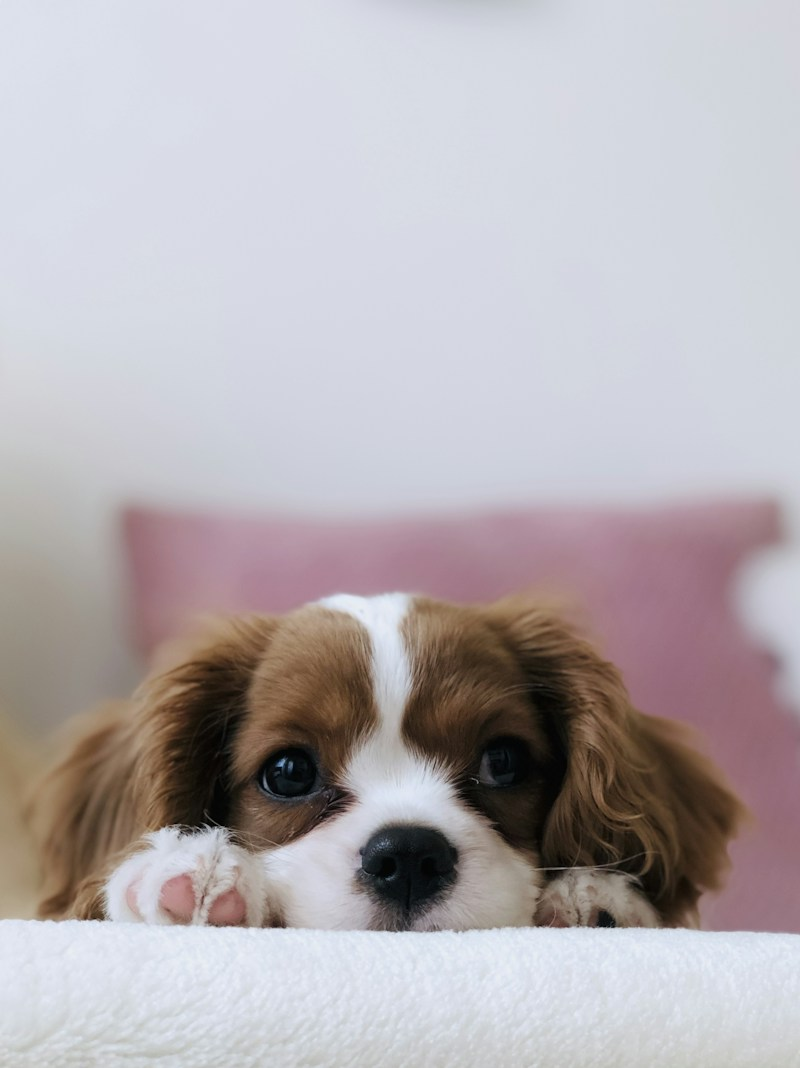

Which animal is this?  dog


Correct! Well done.



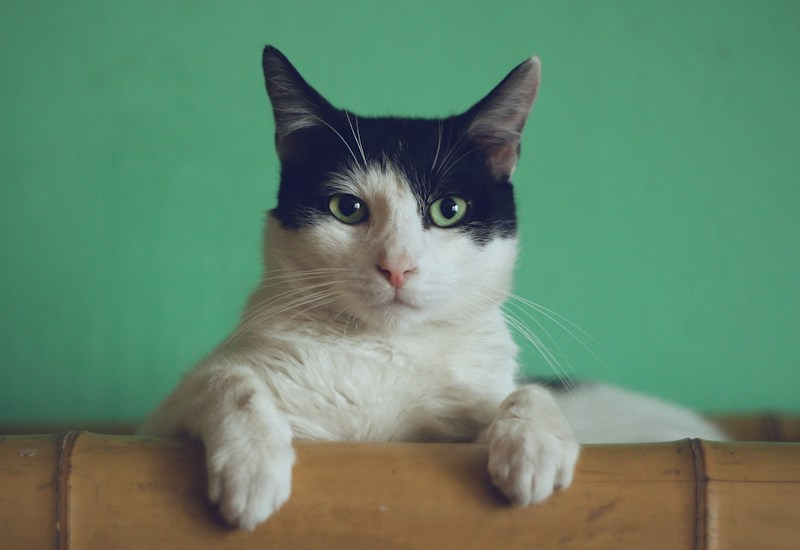

Which animal is this?  cat


Correct! Well done.



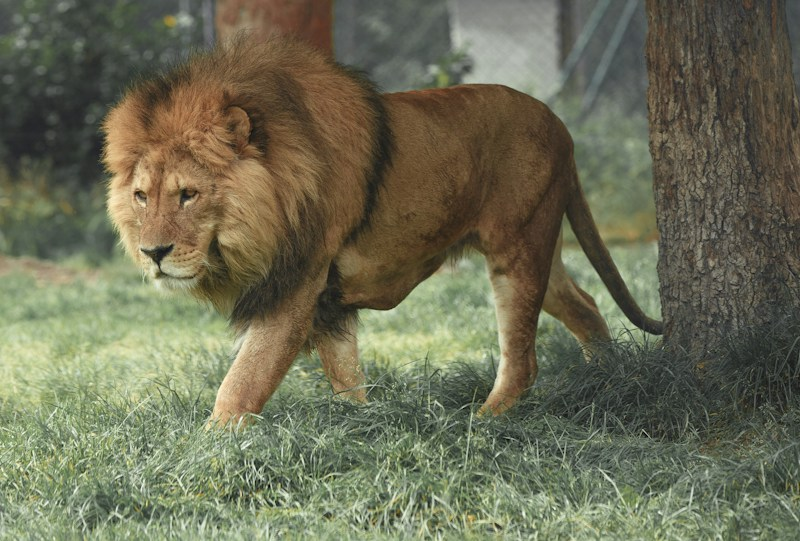

Which animal is this?  lion


Correct! Well done.

Game finished!
Your final score: 3 out of 3


In [21]:

import requests
from IPython.display import display, Image as IPImage

# Sample images and their answers
images = [
    {
        "url": "https://images.unsplash.com/photo-1560807707-8cc77767d783?w=800",
        "answer": "dog"
    },
    {
        "url": "https://images.unsplash.com/photo-1514888286974-6c03e2ca1dba?w=800",
        "answer": "cat"
    },
    {
        "url": "https://images.unsplash.com/photo-1546182990-dffeafbe841d?w=800",
        "answer": "lion"
    }
]

def play_game():
    score = 0

    print("Welcome to the Image Recognition Game!")
    print("Identify the animal shown in each image.")
    print("Type 'quit' to exit.\n")

    for item in images:
        try:
            response = requests.get(item["url"], timeout=15)
            response.raise_for_status()

            display(IPImage(data=response.content))

            guess = input("Which animal is this? ").strip().lower()

            if guess == "quit":
                break

            if guess == item["answer"]:
                print("Correct! Well done.\n")
                score += 1
            else:
                print("Incorrect. The answer is:", item["answer"], "\n")

        except requests.RequestException as error:
            print("Could not load the image:", error)
            continue

    print("Game finished!")
    print("Your final score:", score, "out of", len(images))

play_game()


In [23]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [25]:
import random
import ipywidgets as widgets
from IPython.display import display, clear_output

# Game choices
choices = ["Rock", "Paper", "Scissors"]

# Scoreboard
player_score = 0
computer_score = 0
draws = 0

# Display area
output = widgets.Output()

# Game title
title = widgets.HTML(
    "<h2 style='color: royalblue;'>🎮 Rock, Paper, Scissors</h2>"
    "<p>Choose your move and challenge the computer!</p>"
)

# Buttons
rock_button = widgets.Button(
    description="🪨 Rock",
    button_style="info"
)

paper_button = widgets.Button(
    description="📄 Paper",
    button_style="success"
)

scissors_button = widgets.Button(
    description="✂️ Scissors",
    button_style="warning"
)

reset_button = widgets.Button(
    description="🔄 Reset Game",
    button_style="danger"
)

score_label = widgets.HTML()
result_label = widgets.HTML()

def update_score():
    score_label.value = (
        f"<b>Player:</b> {player_score} &nbsp; | &nbsp; "
        f"<b>Computer:</b> {computer_score} &nbsp; | &nbsp; "
        f"<b>Draws:</b> {draws}"
    )

def play_game(player_choice):
    global player_score, computer_score, draws

    computer_choice = random.choice(choices)

    if player_choice == computer_choice:
        message = "🤝 It's a draw!"
        draws += 1

    elif (
        (player_choice == "Rock" and computer_choice == "Scissors")
        or (player_choice == "Paper" and computer_choice == "Rock")
        or (player_choice == "Scissors" and computer_choice == "Paper")
    ):
        message = "🎉 You win this round!"
        player_score += 1

    else:
        message = "🤖 Computer wins this round!"
        computer_score += 1

    result_label.value = (
        f"<h3>You chose: {player_choice}</h3>"
        f"<h3>Computer chose: {computer_choice}</h3>"
        f"<h2>{message}</h2>"
    )

    update_score()

def reset_game(button):
    global player_score, computer_score, draws

    player_score = 0
    computer_score = 0
    draws = 0

    result_label.value = "<p>Game reset! Choose your move.</p>"
    update_score()

rock_button.on_click(lambda button: play_game("Rock"))
paper_button.on_click(lambda button: play_game("Paper"))
scissors_button.on_click(lambda button: play_game("Scissors"))
reset_button.on_click(reset_game)

update_score()

display(title)
display(widgets.HBox([rock_button, paper_button, scissors_button]))
display(result_label)
display(score_label)
display(reset_button)

HTML(value="<h2 style='color: royalblue;'>🎮 Rock, Paper, Scissors</h2><p>Choose your move and challenge the co…

HTML(value='')

HTML(value='<b>Player:</b> 0 &nbsp; | &nbsp; <b>Computer:</b> 0 &nbsp; | &nbsp; <b>Draws:</b> 0')

Button(button_style='danger', description='🔄 Reset Game', style=ButtonStyle())

In [29]:
import cv2

# Load the pre-trained face detection model
model_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_detector = cv2.CascadeClassifier(model_path)

# Check that the model loaded correctly
if face_detector.empty():
    raise RuntimeError(
        "Face detection model could not be loaded."
    )

# Open the webcam (0 means the default camera)
camera = cv2.VideoCapture(0)

if not camera.isOpened():
    camera.release()
    raise RuntimeError(
        "Webcam not found. Check camera connection and permissions."
    )

print("Face detection started!")
print("Press Q in the camera window to stop.")

try:
    while True:
        # Read a frame from the webcam
        success, frame = camera.read()

        if not success:
            print("Could not read webcam frame.")
            break

        # Convert the frame to grayscale
        gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        )

        # Detect faces
        faces = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        # Draw rectangles around detected faces
        for (x, y, w, h) in faces:
            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

        # Display the number of detected faces
        cv2.putText(
            frame,
            "Faces detected: " + str(len(faces)),
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        # Show the camera feed
        cv2.imshow("Real-Time Face Detection", frame)

        # Press Q to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()
    print("Face detection stopped.")

Face detection started!
Press Q in the camera window to stop.
Face detection stopped.


In [31]:
%pip install opencv-python mediapipe deepface

  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'F:\\anacondaa\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [35]:
import cv2
import time

# Optional libraries
try:
    import mediapipe as mp
    hands_available = hasattr(mp, "solutions")
except Exception:
    hands_available = False

try:
    from deepface import DeepFace
    deepface_available = True
except Exception as e:
    deepface_available = False
    print("DeepFace unavailable:", e)

# OpenCV face, eye and smile detectors
cascade_folder = cv2.data.haarcascades

face_detector = cv2.CascadeClassifier(
    cascade_folder + "haarcascade_frontalface_default.xml"
)
eye_detector = cv2.CascadeClassifier(
    cascade_folder + "haarcascade_eye.xml"
)
smile_detector = cv2.CascadeClassifier(
    cascade_folder + "haarcascade_smile.xml"
)

if face_detector.empty() or eye_detector.empty() or smile_detector.empty():
    raise RuntimeError("OpenCV Haar cascade models failed to load.")

# Hand detector
hands = None
if hands_available:
    try:
        hands = mp.solutions.hands.Hands(
            static_image_mode=False,
            max_num_hands=2,
            min_detection_confidence=0.6,
            min_tracking_confidence=0.5
        )
    except Exception as e:
        print("Hand detection unavailable:", e)

# Cache facial attribute predictions to reduce processing
last_analysis_time = 0
cached_gender = "Not analyzed"
cached_emotion = "Not analyzed"

# Start webcam
camera = cv2.VideoCapture(0)

if not camera.isOpened():
    camera.release()
    raise RuntimeError(
        "Cannot open webcam. Check camera permissions or try camera index 1."
    )

print("Detection started. Press Q in the webcam window to quit.")

try:
    while True:
        success, frame = camera.read()

        if not success:
            print("Could not read webcam frame.")
            break

        frame = cv2.flip(frame, 1)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # 1. FACE DETECTION
        faces = face_detector.detectMultiScale(
            gray,
            scaleFactor=1.2,
            minNeighbors=5,
            minSize=(60, 60)
        )

        for (x, y, w, h) in faces:
            cv2.rectangle(
                frame, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )

            face_gray = gray[y:y+h, x:x+w]
            face_color = frame[y:y+h, x:x+w]

            # 2. EYE DETECTION
            eyes = eye_detector.detectMultiScale(
                face_gray,
                scaleFactor=1.1,
                minNeighbors=6,
                minSize=(15, 15)
            )

            for (ex, ey, ew, eh) in eyes:
                cv2.rectangle(
                    frame,
                    (x + ex, y + ey),
                    (x + ex + ew, y + ey + eh),
                    (255, 0, 0), 2
                )

            # 3. SMILE DETECTION
            # Search mainly in the lower half of the face
            lower_face = face_gray[h // 2:h, :]
            smiles = smile_detector.detectMultiScale(
                lower_face,
                scaleFactor=1.7,
                minNeighbors=20,
                minSize=(25, 15)
            )

            if len(smiles) > 0:
                cv2.putText(
                    frame, "Possible smile",
                    (x, y + h + 22),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (0, 255, 255), 2
                )

            # 4 & 5. GENDER AND EMOTION ESTIMATION
            # Run at intervals because neural-network inference is slower
            now = time.time()

            if deepface_available and now - last_analysis_time > 3:
                try:
                    result = DeepFace.analyze(
                        img_path=face_color.copy(),
                        actions=["gender", "emotion"],
                        detector_backend="skip",
                        enforce_detection=False,
                        silent=True
                    )

                    if isinstance(result, list):
                        result = result[0]

                    cached_gender = result.get(
                        "dominant_gender", "Unknown"
                    )
                    cached_emotion = result.get(
                        "dominant_emotion", "Unknown"
                    )
                    last_analysis_time = now

                except Exception as e:
                    cached_gender = "Unavailable"
                    cached_emotion = "Unavailable"
                    last_analysis_time = now
                    print("Facial analysis error:", e)

            cv2.putText(
                frame, "Gender estimate: " + str(cached_gender),
                (x, max(20, y - 35)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (255, 255, 0), 2
            )

            cv2.putText(
                frame, "Emotion estimate: " + str(cached_emotion),
                (x, max(20, y - 12)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5, (255, 255, 0), 2
            )

        # 6. BASIC HAND GESTURE DETECTION
        if hands is not None:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            try:
                hand_results = hands.process(rgb)

                if hand_results.multi_hand_landmarks:
                    height, width = frame.shape[:2]

                    for hand_landmarks in hand_results.multi_hand_landmarks:
                        points = hand_landmarks.landmark

                        # Draw hand landmark connections
                        mp.solutions.drawing_utils.draw_landmarks(
                            frame,
                            hand_landmarks,
                            mp.solutions.hands.HAND_CONNECTIONS
                        )

                        # Count extended fingers.
                        # This simple rule works best with palm facing camera.
                        finger_tips = [8, 12, 16, 20]
                        finger_pips = [6, 10, 14, 18]

                        extended = sum(
                            points[tip].y < points[pip].y
                            for tip, pip in zip(finger_tips, finger_pips)
                        )

                        if extended >= 4:
                            gesture = "Open palm"
                        elif extended == 0:
                            gesture = "Possible fist"
                        elif extended == 1:
                            gesture = "One finger"
                        elif extended == 2:
                            gesture = "Two fingers"
                        else:
                            gesture = "Hand gesture"

                        wrist_x = int(points[0].x * width)
                        wrist_y = int(points[0].y * height)

                        cv2.putText(
                            frame, gesture,
                            (wrist_x, max(25, wrist_y - 15)),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.7, (0, 165, 255), 2
                        )

            except Exception as e:
                cv2.putText(
                    frame, "Hand processing error",
                    (10, 90),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (0, 0, 255), 2
                )

        # Display face count
        cv2.putText(
            frame, "Faces detected: " + str(len(faces)),
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8, (0, 255, 0), 2
        )

        cv2.imshow("AI Multi-Feature Detection", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()

    if hands is not None:
        hands.close()

    print("Camera closed.")

DeepFace unavailable: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject
Detection started. Press Q in the webcam window to quit.
Camera closed.


In [37]:
%pip install -U ultralytics opencv-python mediapipe deepface

Note: you may need to restart the kernel to use updated packages.
  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ---------------------- ----------------- 0.8/1.4 MB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.8 MB/s eta 0:00:00
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
   ---------------------------------------- 0.0/22.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/22.8 MB 3.4 MB/s eta 0:00:07
   -- ------------------------------------- 1.6/22.8 MB 4.0 MB/s eta 0:00:06
   ---- ----------------------------------- 2.6/22.8 MB 4.3 MB/s eta 0:00:05
   ------ --------------------------------- 3.7/22.8 MB 4.5 MB/s eta 0:00:05
   --------- -----------------

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'f:\\anacondaa\\lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [39]:
import cv2
import time
from ultralytics import YOLO

# Load pretrained YOLO model
print("Loading YOLO model...")
model = YOLO("yolo26n.pt")

# Load OpenCV face, eye and smile detectors
folder = cv2.data.haarcascades

face_model = cv2.CascadeClassifier(
    folder + "haarcascade_frontalface_default.xml"
)
eye_model = cv2.CascadeClassifier(
    folder + "haarcascade_eye.xml"
)
smile_model = cv2.CascadeClassifier(
    folder + "haarcascade_smile.xml"
)

if face_model.empty() or eye_model.empty() or smile_model.empty():
    raise RuntimeError("Could not load OpenCV face/eye/smile models.")

# Optional MediaPipe hand detection
hands = None
mp = None

try:
    import mediapipe as mp

    if hasattr(mp, "solutions"):
        hands = mp.solutions.hands.Hands(
            max_num_hands=2,
            min_detection_confidence=0.6,
            min_tracking_confidence=0.5
        )
        print("Hand gesture detection enabled.")
    else:
        print("This MediaPipe version needs its newer Tasks API.")
except Exception as e:
    print("Hand detection disabled:", e)

# Optional DeepFace emotion/gender estimation
DeepFace = None

try:
    from deepface import DeepFace
    print("Facial attribute estimation enabled.")
except Exception as e:
    print("DeepFace unavailable:", e)

# Cached estimates to reduce repeated inference
last_analysis = 0
emotion_text = "Not analyzed"
gender_text = "Not analyzed"

# Open webcam
camera = cv2.VideoCapture(0)

if not camera.isOpened():
    camera.release()
    raise RuntimeError(
        "Webcam could not open. Close other camera apps "
        "and check Windows camera permissions."
    )

print("Project running. Press Q in the video window to quit.")

try:
    while True:
        ok, frame = camera.read()

        if not ok:
            print("Unable to read webcam.")
            break

        frame = cv2.flip(frame, 1)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # =========================================
        # 1. YOLO OBJECT DETECTION
        # =========================================
        result = model.predict(
            source=frame,
            imgsz=640,
            conf=0.35,
            verbose=False
        )[0]

        # Draw YOLO boxes and labels
        frame = result.plot()

        # =========================================
        # 2. FACE, EYE AND SMILE DETECTION
        # =========================================
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        faces = face_model.detectMultiScale(
            gray,
            scaleFactor=1.2,
            minNeighbors=5,
            minSize=(60, 60)
        )

        for (x, y, w, h) in faces:
            cv2.rectangle(
                frame, (x, y), (x + w, y + h),
                (0, 255, 0), 2
            )

            face_gray = gray[y:y+h, x:x+w]
            face_color = frame[y:y+h, x:x+w]

            # Eye detection
            eyes = eye_model.detectMultiScale(
                face_gray,
                scaleFactor=1.1,
                minNeighbors=6,
                minSize=(15, 15)
            )

            for (ex, ey, ew, eh) in eyes:
                cv2.rectangle(
                    frame,
                    (x + ex, y + ey),
                    (x + ex + ew, y + ey + eh),
                    (255, 0, 0), 2
                )

            # Smile detection
            lower_face = face_gray[h // 2:, :]

            smiles = smile_model.detectMultiScale(
                lower_face,
                scaleFactor=1.7,
                minNeighbors=20,
                minSize=(25, 15)
            )

            if len(smiles) > 0:
                cv2.putText(
                    frame, "Possible smile",
                    (x, min(frame.shape[0] - 10, y + h + 22)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6, (0, 255, 255), 2
                )

            # =====================================
            # 3. GENDER AND EMOTION ESTIMATES
            # =====================================
            if DeepFace is not None and time.time() - last_analysis > 3:
                try:
                    prediction = DeepFace.analyze(
                        img_path=face_color.copy(),
                        actions=["gender", "emotion"],
                        detector_backend="skip",
                        enforce_detection=False,
                        silent=True
                    )

                    if isinstance(prediction, list):
                        prediction = prediction[0]

                    gender_text = prediction.get(
                        "dominant_gender", "Unknown"
                    )
                    emotion_text = prediction.get(
                        "dominant_emotion", "Unknown"
                    )

                except Exception as e:
                    gender_text = "Unavailable"
                    emotion_text = "Unavailable"
                    print("Facial analysis error:", e)

                last_analysis = time.time()

            cv2.putText(
                frame, "Gender estimate: " + str(gender_text),
                (x, max(20, y - 35)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45, (255, 255, 0), 2
            )

            cv2.putText(
                frame, "Emotion estimate: " + str(emotion_text),
                (x, max(20, y - 12)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.45, (255, 255, 0), 2
            )

        # =========================================
        # 4. BASIC HAND GESTURE DETECTION
        # =========================================
        if hands is not None:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            hand_result = hands.process(rgb)

            if hand_result.multi_hand_landmarks:
                for hand in hand_result.multi_hand_landmarks:
                    mp.solutions.drawing_utils.draw_landmarks(
                        frame,
                        hand,
                        mp.solutions.hands.HAND_CONNECTIONS
                    )

                    points = hand.landmark

                    # Basic finger extension heuristic
                    tips = [8, 12, 16, 20]
                    pips = [6, 10, 14, 18]

                    extended = sum(
                        points[t].y < points[p].y
                        for t, p in zip(tips, pips)
                    )

                    if extended == 4:
                        gesture = "Open palm"
                    elif extended == 0:
                        gesture = "Possible fist"
                    elif extended == 1:
                        gesture = "One finger"
                    elif extended == 2:
                        gesture = "Two fingers"
                    else:
                        gesture = "Hand gesture"

                    wrist = points[0]
                    px = int(wrist.x * frame.shape[1])
                    py = int(wrist.y * frame.shape[0])

                    cv2.putText(
                        frame, gesture,
                        (px, max(25, py - 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.65, (0, 165, 255), 2
                    )

        # Face count
        cv2.putText(
            frame,
            "Faces detected: " + str(len(faces)),
            (10, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (0, 255, 0), 2
        )

        cv2.imshow("YOLO Multi-Feature Detection", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    camera.release()
    cv2.destroyAllWindows()

    if hands is not None:
        hands.close()

    print("Detection stopped.")

Loading YOLO model...
Hand detection disabled: name 'audio_classifier' is not defined
DeepFace unavailable: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject
Project running. Press Q in the video window to quit.
Detection stopped.
